# Pandas essentials

A runnable tour of the pandas operations I use most, on two datasets:

- **French referendum results** at town level (36,565 towns), with the region and
  department reference tables from the [pandas assignment](pandas/);
- a **synthetic daily price series** for the time-series section (geometric Brownian
  motion, *not* market data).

Sections: loading · index and columns · selection · cleaning · merging and aggregation ·
time series · plotting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)

## 1. Loading and inspecting

In [2]:
referendum = pd.read_csv("pandas/data/referendum.csv", sep=";")
regions = pd.read_csv("pandas/data/regions.csv")
departments = pd.read_csv("pandas/data/departments.csv")

print(referendum.shape)
referendum.head()

(36791, 9)


,Department code,Department name,Town code,Town name,Registered,Abstentions,Null,Choice A,Choice B
0,1,AIN,1,L'Abergement-Clémenciat,592,84,9,154,345
1,1,AIN,2,L'Abergement-de-Varey,215,36,5,66,108
2,1,AIN,4,Ambérieu-en-Bugey,8205,1698,126,2717,3664
3,1,AIN,5,Ambérieux-en-Dombes,1152,170,18,280,684
4,1,AIN,6,Ambléon,105,17,1,35,52


In [3]:
referendum.info()

<class 'pandas.DataFrame'>
RangeIndex: 36791 entries, 0 to 36790
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Department code  36791 non-null  str  
 1   Department name  36791 non-null  str  
 2   Town code        36791 non-null  int64
 3   Town name        36791 non-null  str  
 4   Registered       36791 non-null  int64
 5   Abstentions      36791 non-null  int64
 6   Null             36791 non-null  int64
 7   Choice A         36791 non-null  int64
 8   Choice B         36791 non-null  int64
dtypes: int64(6), str(3)
memory usage: 2.5 MB


In [4]:
referendum.describe().round(1)

,Town code,Registered,Abstentions,Null,Choice A,Choice B
count,36791.0,36791.0,36791.0,36791.0,36791.0,36791.0
mean,251.7,1251.1,256.7,19.1,426.7,548.6
std,181.7,8595.8,2075.4,96.8,3303.0,3346.6
min,1.0,6.0,0.0,0.0,0.0,0.0
25%,105.0,160.0,23.0,2.0,49.0,81.0
50%,218.0,337.0,49.0,6.0,108.0,169.0
75%,361.0,807.0,120.0,14.0,268.0,402.0
max,909.0,1253322.0,248755.0,12093.0,506594.0,485880.0


## 2. Index and columns

In [5]:
towns = referendum.copy()
towns.columns = towns.columns.str.lower().str.replace(" ", "_")   # snake_case names
towns = towns.rename(columns={"choice_a": "yes", "choice_b": "no"})
towns = towns.set_index(["department_code", "town_code"])         # hierarchical index
towns.head(3)

department_name                town_name  \
department_code town_code                                            
1               1                     AIN  L'Abergement-Clémenciat   
                2                     AIN    L'Abergement-de-Varey   
                4                     AIN        Ambérieu-en-Bugey   

                           registered  abstentions  null   yes    no  
department_code town_code                                             
1               1                 592           84     9   154   345  
                2                 215           36     5    66   108  
                4                8205         1698   126  2717  3664

In [6]:
towns.reset_index().iloc[::-1].reset_index(drop=True).head(3)     # reverse row order

,department_code,town_code,department_name,town_name,registered,abstentions,null,yes,no
0,ZZ,11,FRANCAIS DE L'ETRANGER,"Europe de l'est, Asie, Océanie",80061,42911,488,13975,22687
1,ZZ,10,FRANCAIS DE L'ETRANGER,"Afrique Centre, Sud et Est",89859,46782,566,17008,25503
2,ZZ,9,FRANCAIS DE L'ETRANGER,Afrique Nord-Ouest,98997,59887,321,22116,16673


## 3. Selection

In [7]:
towns.loc[("75", 56), ["town_name", "registered", "yes", "no"]]   # Paris by label

town_name       Paris
registered    1253322
yes            506594
no             485880
Name: (75, 56), dtype: object

In [8]:
df = towns.reset_index()
big = df[df["registered"] > 100_000]                                # boolean mask
coast = df[df["department_code"].isin(["29", "56", "22"])]         # Brittany coast
saints = df[df["town_name"].str.contains(r"^Saint-", regex=True)]
mid = df[df["registered"].between(1_000, 2_000)]
print(len(big), len(coast), len(saints), len(mid))

15 917 3919 3597


In [9]:
df.nlargest(5, "registered")[["town_name", "registered"]]

,town_name,registered
30795,Paris,1253322
4458,Marseille,484206
28530,Lyon,292869
12423,Toulouse,249386
2019,Nice,214405


In [10]:
threshold = df["registered"].quantile(0.99)
df.query("registered > @threshold and abstentions / registered > 0.3")[
    ["town_name", "registered", "abstentions"]
].head()

,town_name,registered,abstentions
23541,Roubaix,46047,14474
23626,Tourcoing,61009,19319
28251,Mulhouse,54630,16453
28661,Vaulx-en-Velin,20877,6318
36293,Aubervilliers,26215,7914


In [11]:
train = df.sample(frac=0.7, random_state=0)   # 70 / 30 split without sklearn
test = df.drop(train.index)
len(train), len(test)

(25754, 11037)

## 4. Cleaning

A small table with the usual problems: missing values, duplicates, wrong types.

In [12]:
students = pd.DataFrame({
    "name": ["anastasia", "dima", "katherine", "james", "emily", "michael", "matthew", "laura", "kevin", "jonas", "dima"],
    "score": [12.5, 9, 16.5, np.nan, 9, 20, 14.5, np.nan, 8, 19, 9],
    "attempts": ["1", "3", "2", "3", "2", "3", "1", "1", "2", "1", "3"],
    "qualify": ["yes", "no", "yes", "no", "no", "yes", "yes", "no", "no", "yes", "no"],
})
students.isna().sum()

name        0
score       2
attempts    0
qualify     0
dtype: int64

In [13]:
clean = (
    students
    .drop_duplicates()
    .assign(
        name=lambda d: d["name"].str.capitalize(),
        attempts=lambda d: d["attempts"].astype(int),
        score_filled=lambda d: d["score"].fillna(d["score"].median()),
        qualify=lambda d: d["qualify"].map({"yes": True, "no": False}),
    )
)
clean["grade"] = pd.cut(clean["score_filled"], bins=[0, 10, 15, 20], labels=["low", "mid", "high"])
clean

,name,score,attempts,qualify,score_filled,grade
0,Anastasia,12.5,1,True,12.5,mid
1,Dima,9.0,3,False,9.0,low
2,Katherine,16.5,2,True,16.5,high
3,James,NaN,3,False,13.5,mid
4,Emily,9.0,2,False,9.0,low
5,Michael,20.0,3,True,20.0,high
6,Matthew,14.5,1,True,14.5,mid
7,Laura,NaN,1,False,13.5,mid
8,Kevin,8.0,2,False,8.0,low
9,Jonas,19.0,1,True,19.0,high


In [14]:
s = pd.Series([1.0, np.nan, np.nan, 4.0, np.nan])
pd.DataFrame({"ffill": s.ffill(), "bfill": s.bfill(), "interpolate": s.interpolate()})

,ffill,bfill,interpolate
0,1.0,1.0,1.0
1,1.0,4.0,2.0
2,1.0,4.0,3.0
3,4.0,4.0,4.0
4,4.0,NaN,4.0


## 5. Merging and aggregation

Department codes are written `1` in the referendum file and `01` in the reference table:
they are padded before the join. Overseas departments and French citizens abroad have codes
starting with `Z` and are dropped by the inner join.

In [15]:
areas = departments.merge(regions, left_on="region_code", right_on="code", suffixes=("_dep", "_reg"))
areas = areas[["code_reg", "name_reg", "code_dep", "name_dep"]]

votes = (
    referendum
    .assign(code_dep=referendum["Department code"].str.zfill(2))
    .merge(areas, on="code_dep", how="inner", validate="many_to_one")
)
print(f"{len(referendum) - len(votes)} rows dropped (overseas and abroad)")

226 rows dropped (overseas and abroad)


In [16]:
by_region = votes.groupby("name_reg").agg(
    towns=("Town code", "size"),
    registered=("Registered", "sum"),
    abstentions=("Abstentions", "sum"),
    yes=("Choice A", "sum"),
    no=("Choice B", "sum"),
    largest_town=("Registered", "max"),
)
by_region["turnout"] = 1 - by_region["abstentions"] / by_region["registered"]
by_region["yes_share"] = by_region["yes"] / (by_region["yes"] + by_region["no"])
by_region.sort_values("yes_share", ascending=False).round(3)

,towns,registered,abstentions,yes,no,largest_town,turnout,yes_share
name_reg,,,,,,,,
Nouvelle-Aquitaine,4505,4201774,711017,1641249,1777879,136177,0.831,0.480
Bretagne,1270,2380594,364724,944052,1035741,116983,0.847,0.477
Île-de-France,1281,6942361,1515884,2536620,2803860,1253322,0.782,0.475
Occitanie,4565,4008516,660914,1528980,1755890,249386,0.835,0.465
Pays de la Loire,1502,2605438,412509,922468,1222784,180728,0.842,0.430
Hauts-de-France,3836,4210444,866555,1411257,1872031,122616,0.794,0.430
Normandie,3231,2372779,426075,816972,1094219,112708,0.820,0.427
Auvergne-Rhône-Alpes,4189,5227873,909284,1791857,2444915,292869,0.826,0.423
Bourgogne-Franche-Comté,3831,1997925,358321,668246,937687,81618,0.821,0.416


In [17]:
# Share of towns where "Choice A" won, per region, with a pivot table
votes["winner"] = np.where(votes["Choice A"] > votes["Choice B"], "A", "B")
pd.pivot_table(votes, index="name_reg", columns="winner", values="Town code",
               aggfunc="count", fill_value=0).pipe(lambda t: t.div(t.sum(axis=1), axis=0)).round(2)

winner,A,B
name_reg,,
Auvergne-Rhône-Alpes,0.17,0.83
Bourgogne-Franche-Comté,0.07,0.93
Bretagne,0.30,0.70
Centre-Val de Loire,0.03,0.97
Corse,0.24,0.76
Grand Est,0.02,0.98
Hauts-de-France,0.05,0.95
Normandie,0.05,0.95
Nouvelle-Aquitaine,0.33,0.67


## 6. Time series

A reproducible synthetic price series (geometric Brownian motion, 7% drift, 20% volatility).

In [18]:
rng = np.random.default_rng(4)
dates = pd.bdate_range("2019-01-01", "2023-12-29")
log_returns = rng.normal(0.07 / 252, 0.2 / np.sqrt(252), len(dates))
prices = pd.DataFrame({
    "close": 100 * np.exp(np.cumsum(log_returns)),
    "volume": rng.integers(1_000_000, 5_000_000, len(dates)),
}, index=dates)

prices["return"] = prices["close"].pct_change()
prices["log_return"] = np.log(prices["close"] / prices["close"].shift(1))
prices["sma_50"] = prices["close"].rolling(50).mean()
prices["vol_20d"] = prices["log_return"].rolling(20).std() * np.sqrt(252)  # annualised
prices.dropna().head()

,close,volume,return,log_return,sma_50,vol_20d
2019-03-11,95.631935,1703531,-0.006084,-0.006102,97.802567,0.175513
2019-03-12,95.311169,3928931,-0.003354,-0.003360,97.724596,0.175316
2019-03-13,95.890059,2601395,0.006074,0.006055,97.662015,0.176341
2019-03-14,94.771857,3089623,-0.011661,-0.011730,97.534559,0.168375
2019-03-15,94.358939,1052451,-0.004357,-0.004366,97.381410,0.162873


In [19]:
monthly = prices.resample("ME").agg({"close": "last", "volume": "sum"})
monthly["monthly_return"] = monthly["close"].pct_change()
monthly.tail()

,close,volume,monthly_return
2023-08-31,121.905322,77192075,-0.038832
2023-09-30,121.183114,62827318,-0.005924
2023-10-31,130.460079,57731783,0.076553
2023-11-30,142.393224,69687935,0.091470
2023-12-31,135.812608,72083369,-0.046214


In [20]:
print(f"Annualised volatility: {prices['log_return'].std() * np.sqrt(252):.1%}")
covid = prices.loc["2020-03-01":"2020-06-30"]       # date slicing on a DatetimeIndex
print(f"{len(covid)} trading days between March and June 2020")

Annualised volatility: 20.6%
87 trading days between March and June 2020


In [21]:
# Parsing unusual date formats: year + day of year
raw = pd.DataFrame({"year": [2023, 2023, 2024], "day_of_year": [1, 45, 366]})
pd.to_datetime(raw["year"] * 1000 + raw["day_of_year"], format="%Y%j")

0   2023-01-01
1   2023-02-14
2   2024-12-31
dtype: datetime64[us]

## 7. Plotting

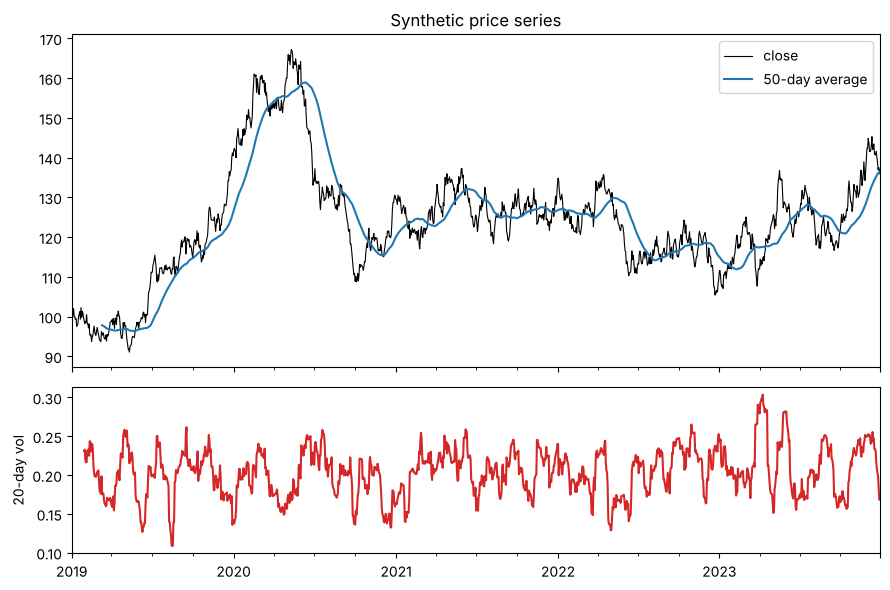

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 6), gridspec_kw={"height_ratios": [2, 1]})
prices["close"].plot(ax=ax1, color="black", lw=0.8, label="close")
prices["sma_50"].plot(ax=ax1, color="tab:blue", label="50-day average")
ax1.legend(); ax1.set_title("Synthetic price series")
prices["vol_20d"].plot(ax=ax2, color="tab:red"); ax2.set_ylabel("20-day vol")
plt.tight_layout()

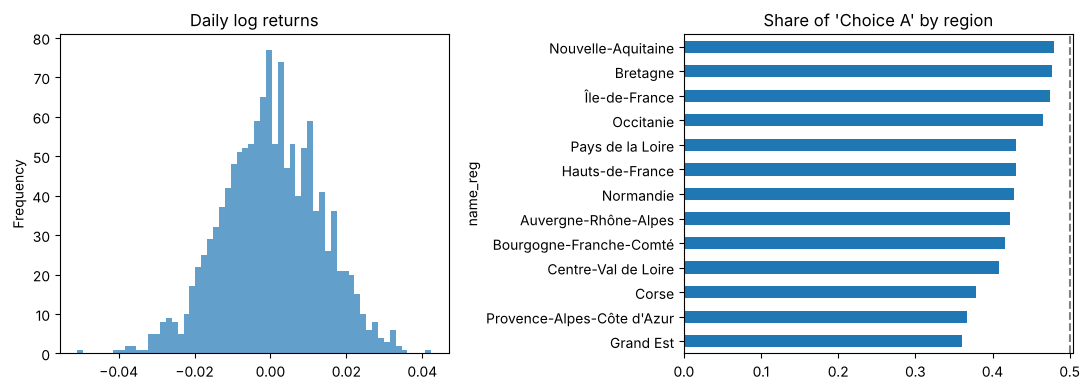

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
prices["log_return"].plot.hist(bins=60, ax=ax1, alpha=0.7, title="Daily log returns")
by_region["yes_share"].sort_values().plot.barh(ax=ax2, title="Share of 'Choice A' by region")
ax2.axvline(0.5, color="grey", ls="--")
plt.tight_layout()